# Chapter 2 — Working with Text Data

Covers the full data pipeline: loading raw text, tokenizing it, building a vocabulary, using byte-pair encoding (BPE), creating input–target pairs for next-token prediction, and building token + positional embeddings.

## 1. Load Raw Text

In [112]:
with open("./resources/the-verdict.txt", "r", encoding="utf-8") as f:
    raw_text = f.read()

print(f"Total number of character: {len(raw_text)}")
print(raw_text[:99])

Total number of character: 20479
I HAD always thought Jack Gisburn rather a cheap genius--though a good fellow enough--so it was no 


## 2. Simple Regex Tokenization

Before using a production tokenizer we build one from scratch to understand the concept.
The regex splits on punctuation and whitespace, keeping the delimiters as separate tokens.

### 2.1 Split Text into Tokens

In [113]:
import re

# split on punctuation characters and whitespace, keeping them as tokens
preprocessed = re.split(r'([,.:;?_!"()\']|--|\s)', raw_text)
preprocessed = [word for word in preprocessed if word.strip()]  # drop empty strings

print(f"Total tokens: {len(preprocessed)}")
print(preprocessed[:30])

Total tokens: 4690
['I', 'HAD', 'always', 'thought', 'Jack', 'Gisburn', 'rather', 'a', 'cheap', 'genius', '--', 'though', 'a', 'good', 'fellow', 'enough', '--', 'so', 'it', 'was', 'no', 'great', 'surprise', 'to', 'me', 'to', 'hear', 'that', ',', 'in']


### 2.2 Build Vocabulary

Collect every unique token, sort alphabetically for a deterministic mapping, then assign each token a sequential integer ID.

In [114]:
all_tokens = sorted(list(set(preprocessed)))
vocab_size = len(all_tokens)

print(f"Vocab length of dataset: {vocab_size}")

Vocab length of dataset: 1130


In [115]:
vocab = {token: integer for integer, token in enumerate(all_tokens)}

In [116]:
for idx, item in enumerate(vocab.items()):
    if idx > 10:
        break
    
    print(item)

('!', 0)
('"', 1)
("'", 2)
('(', 3)
(')', 4)
(',', 5)
('--', 6)
('.', 7)
(':', 8)
(';', 9)
('?', 10)


### 2.3 SimpleTokenizerV1

`encode` → text to list of IDs  
`decode` → list of IDs back to text

> **Limitation:** raises `KeyError` on any word not in the vocabulary.

In [117]:
class SimpleTokenizerV1:
    def __init__(self, vocab):
        self.str_to_int = vocab
        self.int_to_str = {idx: item for item, idx in vocab.items()}

    def encode(self, text):
        preprocessed = re.split(r'([,.:;?_!"()\']|--|\s)', text)
        preprocessed = [word for word in preprocessed if word.strip()]
        ids = [self.str_to_int[item] for item in preprocessed]
        return ids

    def decode(self, ids):
        text = " ".join([self.int_to_str[id] for id in ids])
        text = re.sub(r'\s+([,.?!"()\'])', r'\1', text)
        return text


        

In [118]:
tokenizer = SimpleTokenizerV1(vocab)

text = """
He laughed slightly, without bitterness, and pushed one of the deep arm-chairs forward. "There: make yourself comfortable--and here are the cigars you like."

He placed them at my elbow and continued to wander up and down the room, stopping now and then beneath the picture.
"""

encoded = tokenizer.encode(text)
print(f"Encoded Result: {encoded}", end="\n\n")

decoded = tokenizer.decode(encoded)
print(f"Decoded Result: {decoded}")

Encoded Result: [48, 607, 902, 5, 1109, 221, 5, 157, 805, 729, 722, 988, 320, 172, 467, 7, 1, 95, 8, 655, 1129, 278, 6, 157, 540, 169, 988, 264, 1126, 628, 7, 1, 48, 774, 990, 180, 697, 383, 157, 289, 1016, 1073, 1051, 157, 362, 988, 845, 5, 930, 714, 157, 991, 215, 988, 769, 7]

Decoded Result: He laughed slightly, without bitterness, and pushed one of the deep arm-chairs forward." There : make yourself comfortable -- and here are the cigars you like." He placed them at my elbow and continued to wander up and down the room, stopping now and then beneath the picture.


### 2.4 SimpleTokenizerV2 — Unknown & Special Tokens

Fixes the limitation by adding two special tokens:
- `<|unk|>` — substituted for any out-of-vocabulary word
- `<|endoftext|>` — signals a document boundary (used to separate unrelated texts in one training stream)

In [119]:
all_tokens = sorted(list(set(preprocessed)))
all_tokens.extend(["<|endoftext|>", "<|unk|>"])

vocab_size = len(all_tokens)

print(f"Vocab length of dataset: {vocab_size}")

Vocab length of dataset: 1132


In [120]:
vocab = {token: integer for integer, token in enumerate(all_tokens)}

In [121]:
class SimpleTokenizerV2:
    def __init__(self, vocab):
        self.str_to_int = vocab
        self.int_to_str = {idx: item for item, idx in vocab.items()}

    def encode(self, text):
        preprocessed = re.split(r'([,.:;?_!"()\']|--|\s)', text)
        preprocessed = [word for word in preprocessed if word.strip()]
        preprocessed = [
            item if item in self.str_to_int
            else "<|unk|>" for item in preprocessed
        ]
        ids = [self.str_to_int[item] for item in preprocessed]
        return ids

    def decode(self, ids):
        text = " ".join([self.int_to_str[id] for id in ids])
        text = re.sub(r'\s+([,.?!"()\'])', r'\1', text)
        return text


        

In [122]:
tokenizer = SimpleTokenizerV2(vocab)

text_1 = """
He laughed slightly, without bitterness, and pushed one of the deep arm-chairs forward. "There: make yourself comfortable--and here are the cigars you like."

He placed them at my elbow and continued to wander up and down the room, stopping now and then beneath the picture.
"""

text_2 = """
"How it happened? I can tell you in five minutes--and it didn't take much longer to happen. . . . I can remember now how surprised and pleased I was when I got Mrs. Stroud's note. Of course, deep down, I had always _felt_ there was no one like him--only I had gone with the stream, echoed the usual platitudes about him, till I half got to think he was a failure, one of the kind that are left behind. By Jove, and he _was_ left behind--because he had come to stay! The rest of us had to let ourselves be swept along or go under, but he was high above the current--on everlasting foundations, as you say.

"Well, I went off to the house in my most egregious mood--rather moved, Lord forgive me, at the pathos of poor Stroud's career of failure being crowned by the glory of my painting him! Of course I meant to do the picture for nothing--I told Mrs. Stroud so when she began to stammer something about her poverty. I remember getting off a prodigious phrase about the honour being _mine_--oh, I was princely, my dear Rickham! I was posing to myself like one of my own sitters.
"""


text = " <|endoftext|> ".join((text_1, text_2))
print(text, end="\n\n")

encoded = tokenizer.encode(text)
print(f"Encoded Result: {encoded}", end="\n\n")

decoded = tokenizer.decode(encoded)
print(f"Decoded Result: {decoded}")


He laughed slightly, without bitterness, and pushed one of the deep arm-chairs forward. "There: make yourself comfortable--and here are the cigars you like."

He placed them at my elbow and continued to wander up and down the room, stopping now and then beneath the picture.
 <|endoftext|> 
"How it happened? I can tell you in five minutes--and it didn't take much longer to happen. . . . I can remember now how surprised and pleased I was when I got Mrs. Stroud's note. Of course, deep down, I had always _felt_ there was no one like him--only I had gone with the stream, echoed the usual platitudes about him, till I half got to think he was a failure, one of the kind that are left behind. By Jove, and he _was_ left behind--because he had come to stay! The rest of us had to let ourselves be swept along or go under, but he was high above the current--on everlasting foundations, as you say.

"Well, I went off to the house in my most egregious mood--rather moved, Lord forgive me, at the pathos

## 3. Byte-Pair Encoding (BPE) with tiktoken

GPT-2 uses BPE: an algorithm that iteratively merges the most frequent byte pairs into a single token. This produces a vocabulary of **subword units** — common words get one token, rare words get split into known pieces.

`tiktoken` ships the exact GPT-2 tokenizer (vocab size 50,257).

In [123]:
import tiktoken

tokenizer = tiktoken.get_encoding("gpt2")
tokenizer.n_vocab

50257

#### Encode and decode a text sample

In [124]:
text_1 = """
He laughed slightly, without bitterness, and pushed one of the deep arm-chairs forward. "There: make yourself comfortable--and here are the cigars you like."

He placed them at my elbow and continued to wander up and down the room, stopping now and then beneath the picture.
"""

text_2 = """
"How it happened? I can tell you in five minutes--and it didn't take much longer to happen. . . . I can remember now how surprised and pleased I was when I got Mrs. Stroud's note. Of course, deep down, I had always _felt_ there was no one like him--only I had gone with the stream, echoed the usual platitudes about him, till I half got to think he was a failure, one of the kind that are left behind. By Jove, and he _was_ left behind--because he had come to stay! The rest of us had to let ourselves be swept along or go under, but he was high above the current--on everlasting foundations, as you say.

"Well, I went off to the house in my most egregious mood--rather moved, Lord forgive me, at the pathos of poor Stroud's career of failure being crowned by the glory of my painting him! Of course I meant to do the picture for nothing--I told Mrs. Stroud so when she began to stammer something about her poverty. I remember getting off a prodigious phrase about the honour being _mine_--oh, I was princely, my dear Rickham! I was posing to myself like one of my own sitters.
"""

text = "".join((text_1, text_2))
print(text, end="\n\n")

integers = tokenizer.encode(text, allowed_special={"<|endoftext|>"})
print(integers)


He laughed slightly, without bitterness, and pushed one of the deep arm-chairs forward. "There: make yourself comfortable--and here are the cigars you like."

He placed them at my elbow and continued to wander up and down the room, stopping now and then beneath the picture.

"How it happened? I can tell you in five minutes--and it didn't take much longer to happen. . . . I can remember now how surprised and pleased I was when I got Mrs. Stroud's note. Of course, deep down, I had always _felt_ there was no one like him--only I had gone with the stream, echoed the usual platitudes about him, till I half got to think he was a failure, one of the kind that are left behind. By Jove, and he _was_ left behind--because he had come to stay! The rest of us had to let ourselves be swept along or go under, but he was high above the current--on everlasting foundations, as you say.

"Well, I went off to the house in my most egregious mood--rather moved, Lord forgive me, at the pathos of poor Stroud

In [125]:
strings = tokenizer.decode(integers)
strings

'\nHe laughed slightly, without bitterness, and pushed one of the deep arm-chairs forward. "There: make yourself comfortable--and here are the cigars you like."\n\nHe placed them at my elbow and continued to wander up and down the room, stopping now and then beneath the picture.\n\n"How it happened? I can tell you in five minutes--and it didn\'t take much longer to happen. . . . I can remember now how surprised and pleased I was when I got Mrs. Stroud\'s note. Of course, deep down, I had always _felt_ there was no one like him--only I had gone with the stream, echoed the usual platitudes about him, till I half got to think he was a failure, one of the kind that are left behind. By Jove, and he _was_ left behind--because he had come to stay! The rest of us had to let ourselves be swept along or go under, but he was high above the current--on everlasting foundations, as you say.\n\n"Well, I went off to the house in my most egregious mood--rather moved, Lord forgive me, at the pathos of p

#### BPE subword splitting

Unknown words are split into smaller known pieces. `"kibi"` → `["k", "ibi"]` — no token for the full word exists so BPE decomposes it.

In [126]:
text = "kibi kibi kaba kaba"

integers = tokenizer.encode(text, allowed_special={"<|endoftext|>"})
print(integers)

strings = tokenizer.decode(integers)
print(strings)

for item in integers:
    print(f"{item}: {tokenizer.decode([item])}") 

[74, 27567, 479, 27567, 479, 15498, 479, 15498]
kibi kibi kaba kaba
74: k
27567: ibi
479:  k
27567: ibi
479:  k
15498: aba
479:  k
15498: aba


In [127]:
with open("./resources/the-verdict.txt", "r", encoding="utf-8") as f:
    raw_text = f.read()

enc_text = tokenizer.encode(raw_text)

print(f"Total number of character in raw_text: {len(raw_text)}")
print(raw_text[:99], end="\n\n")

print(f"Total number of character in enc_text: {len(enc_text)}")
print(enc_text[:99])

Total number of character in raw_text: 20479
I HAD always thought Jack Gisburn rather a cheap genius--though a good fellow enough--so it was no 

Total number of character in enc_text: 5145
[40, 367, 2885, 1464, 1807, 3619, 402, 271, 10899, 2138, 257, 7026, 15632, 438, 2016, 257, 922, 5891, 1576, 438, 568, 340, 373, 645, 1049, 5975, 284, 502, 284, 3285, 326, 11, 287, 262, 6001, 286, 465, 13476, 11, 339, 550, 5710, 465, 12036, 11, 6405, 257, 5527, 27075, 11, 290, 4920, 2241, 287, 257, 4489, 64, 319, 262, 34686, 41976, 13, 357, 10915, 314, 2138, 1807, 340, 561, 423, 587, 10598, 393, 28537, 2014, 198, 198, 1, 464, 6001, 286, 465, 13476, 1, 438, 5562, 373, 644, 262, 1466, 1444, 340, 13, 314, 460, 3285, 9074, 13, 46606]


## 4. Input–Target Pairs (Next-Token Prediction)

The training objective: given a sequence of tokens, predict the next one at every position.

```
input:  [t0, t1, t2, t3]
target: [t1, t2, t3, t4]   ← shifted one step to the right
```

This means one sample of length `T` gives `T` training examples simultaneously.

In [128]:
text = "He laughed slightly, without bitterness, and pushed one of the deep arm-chairs forward."

enc_sample = tokenizer.encode(text)

context_size = 4 # length of the input
# the context size of 4 means that the model is trained to look a sequence of 4 words (or token)
# to predict the next word

X = enc_sample[:context_size]
y = enc_sample[1:context_size + 1]

print(f"X: {X}")
print(f"y:      {y}")

X: [1544, 13818, 4622, 11]
y:      [13818, 4622, 11, 1231]


In [129]:
for idx in range(1, context_size + 1):
    context = enc_sample[:idx]
    desired = enc_sample[1:idx + 1]

    print(f"{context} ----> {desired}")

[1544] ----> [13818]
[1544, 13818] ----> [13818, 4622]
[1544, 13818, 4622] ----> [13818, 4622, 11]
[1544, 13818, 4622, 11] ----> [13818, 4622, 11, 1231]


In [130]:
for idx in range(1, context_size + 1):
    context = enc_sample[:idx]
    desired = enc_sample[1:idx + 1]

    print(f"{tokenizer.decode(context)} ----> {tokenizer.decode(desired)}")

He ---->  laughed
He laughed ---->  laughed slightly
He laughed slightly ---->  laughed slightly,
He laughed slightly, ---->  laughed slightly, without


## 5. Dataset & DataLoader

A sliding window generates `(input, target)` pairs from the full token sequence.

- `max_length` = window size (context length)
- `stride` = step between windows; `stride < max_length` creates overlapping windows for more samples

### 5.1 GPTDatasetV1

PyTorch `Dataset` that tokenizes the text once and stores all `(input, target)` tensor pairs.

In [131]:
import torch
from torch.utils.data import DataLoader, Dataset

class GPTDatasetV1(Dataset):
    def __init__(self, txt, tokenizer, max_length, stride):
        self.input_ids = []
        self.target_ids = []

        token_ids = tokenizer.encode(txt, allowed_special={"<|endoftext|>"})
        print(f"length of token_ids: {len(token_ids)}")


        for idx in range(0, len(token_ids) - max_length, stride):
            input_chunk = token_ids[idx: idx + max_length]
            target_chunk = token_ids[idx + 1: idx + max_length + 1]

            self.input_ids.append(torch.tensor(input_chunk))
            self.target_ids.append(torch.tensor(target_chunk))

    def __len__(self):
        return len(self.input_ids)

    def __getitem__(self, idx):
        return self.input_ids[idx], self.target_ids[idx]

### 5.2 create_dataloader_v1

In [132]:
def create_dataloader_v1(
    txt,           # raw text string to tokenize and chunk
    batch_size=4,  # number of samples per batch
    max_length=256,# number of tokens in each input/target chunk (context window)
    stride=128,    # how many tokens to slide the window forward; overlap when stride < max_length
    shuffle=True,  # shuffle batches each epoch (disable for evaluation)
    drop_last=True,# drop the final incomplete batch so all batches are equal size
    num_workers=10 # parallel workers for data loading
):
    tokenizer = tiktoken.get_encoding("gpt2")

    dataset = GPTDatasetV1(txt, tokenizer, max_length, stride)

    dataloader = DataLoader(
        dataset,
        batch_size=batch_size,
        shuffle=shuffle,
        drop_last=drop_last,
        num_workers=num_workers
    )

    return dataloader

### 5.3 Verify — Inspect a Batch

Each batch is `[inputs, targets]` both of shape `[batch_size, max_length]`. Notice every row in `targets` is the same row in `inputs` shifted one position to the right.

In [133]:
with open("./resources/the-verdict.txt", "r", encoding="utf-8") as f:
    raw_text = f.read()

dataloader = create_dataloader_v1(
    raw_text,
    batch_size=8,
    max_length=4,
    stride=4,
    shuffle=False,
    num_workers=0
)

data_iter = iter(dataloader)
print(data_iter)

length of token_ids: 5145


In [134]:
next_batch = next(data_iter)
print(next_batch)

[tensor([[   40,   367,  2885,  1464],
        [ 1807,  3619,   402,   271],
        [10899,  2138,   257,  7026],
        [15632,   438,  2016,   257],
        [  922,  5891,  1576,   438],
        [  568,   340,   373,   645],
        [ 1049,  5975,   284,   502],
        [  284,  3285,   326,    11]]), tensor([[  367,  2885,  1464,  1807],
        [ 3619,   402,   271, 10899],
        [ 2138,   257,  7026, 15632],
        [  438,  2016,   257,   922],
        [ 5891,  1576,   438,   568],
        [  340,   373,   645,  1049],
        [ 5975,   284,   502,   284],
        [ 3285,   326,    11,   287]])]


In [135]:
next_batch = next(data_iter)
print(next_batch)

[tensor([[  287,   262,  6001,   286],
        [  465, 13476,    11,   339],
        [  550,  5710,   465, 12036],
        [   11,  6405,   257,  5527],
        [27075,    11,   290,  4920],
        [ 2241,   287,   257,  4489],
        [   64,   319,   262, 34686],
        [41976,    13,   357, 10915]]), tensor([[  262,  6001,   286,   465],
        [13476,    11,   339,   550],
        [ 5710,   465, 12036,    11],
        [ 6405,   257,  5527, 27075],
        [   11,   290,  4920,  2241],
        [  287,   257,  4489,    64],
        [  319,   262, 34686, 41976],
        [   13,   357, 10915,   314]])]


## 6. Token Embeddings

Token IDs are integers — they carry no geometric meaning and cannot be fed into a neural network directly. An **embedding layer** is a learnable lookup table that maps each integer ID to a dense float vector.

`nn.Embedding(vocab_size, dim)` → weight matrix of shape `[vocab_size, dim]`.  
Looking up token ID `i` returns row `i` of that matrix.

### 6.1 Toy Example (vocab=6, dim=3)

Small numbers so the full weight matrix is readable and the lookup is easy to verify by eye.

In [136]:
# quick fox is in the house
input_ids = torch.tensor([2, 3, 5, 1])

vocab_size = 6
output_dim = 3

torch.manual_seed(123)
embedding_layer = torch.nn.Embedding(vocab_size, output_dim)

In [137]:
embedding_layer.weight

Parameter containing:
tensor([[ 0.3374, -0.1778, -0.1690],
        [ 0.9178,  1.5810,  1.3010],
        [ 1.2753, -0.2010, -0.1606],
        [-0.4015,  0.9666, -1.1481],
        [-1.1589,  0.3255, -0.6315],
        [-2.8400, -0.7849, -1.4096]], requires_grad=True)

In [138]:
print(embedding_layer(torch.tensor([3])))

tensor([[-0.4015,  0.9666, -1.1481]], grad_fn=<EmbeddingBackward0>)


In [139]:
print(embedding_layer(input_ids))

tensor([[ 1.2753, -0.2010, -0.1606],
        [-0.4015,  0.9666, -1.1481],
        [-2.8400, -0.7849, -1.4096],
        [ 0.9178,  1.5810,  1.3010]], grad_fn=<EmbeddingBackward0>)


### 6.2 GPT-2 Scale (vocab=50257, dim=256)

Real embedding table. After embedding, `inputs` of shape `[batch, seq_len]` becomes `[batch, seq_len, 256]`.

In [140]:
vocab_size = 50257
output_dim = 256

token_embedding_layer = torch.nn.Embedding(vocab_size, output_dim)
token_embedding_layer

Embedding(50257, 256)

In [141]:
max_length = 4
dataloader = create_dataloader_v1(
    raw_text,
    batch_size=8,
    max_length=max_length,
    stride=max_length,
    shuffle=False,
    num_workers=0
)

data_iter = iter(dataloader)
print(data_iter)

length of token_ids: 5145


In [142]:
inputs, targets = next(data_iter)

In [143]:
print(f"Token IDs:\n{inputs}", end="\n\n")
print(f"Inputs Shape:\n{inputs.shape}", end="\n\n")

Token IDs:
tensor([[   40,   367,  2885,  1464],
        [ 1807,  3619,   402,   271],
        [10899,  2138,   257,  7026],
        [15632,   438,  2016,   257],
        [  922,  5891,  1576,   438],
        [  568,   340,   373,   645],
        [ 1049,  5975,   284,   502],
        [  284,  3285,   326,    11]])

Inputs Shape:
torch.Size([8, 4])



In [144]:
token_embedding = token_embedding_layer(inputs)
print(token_embedding.shape)

torch.Size([8, 4, 256])


## 7. Positional Embeddings

Attention has no concept of order — it treats tokens as a set. We fix this by adding a **positional embedding**: a learned vector for each position `0 … context_length-1`.

```
final input = token_embedding + positional_embedding
```

Both have shape `[seq_len, dim]` so they add element-wise.

In [145]:
context_length = max_length
pos_embedding_layer = torch.nn.Embedding(context_length, output_dim)

In [146]:
torch.arange(max_length)

tensor([0, 1, 2, 3])

In [147]:
pos_embedding = pos_embedding_layer(torch.arange(max_length))
pos_embedding.shape

torch.Size([4, 256])

In [148]:
input_embedding = token_embedding + pos_embedding
input_embedding.shape

torch.Size([8, 4, 256])

# Chapter 3 — Coding Attention Mechanisms

Implements attention from first principles: simple self-attention, scaled dot-product attention, Q/K/V projections, and packages it all into a reusable `nn.Module`.

## 1. Simple Self-Attention (from scratch)

Self-attention lets each token "look at" every other token and decide how much to attend to it. The result for each token is a weighted blend of all other tokens — called the **context vector**.

Formula for one query token:
```
attn_score[i] = dot(query, key_i)       # how relevant is token i?
attn_weight[i] = softmax(attn_score)[i] # normalise to sum = 1
context_vec    = Σ attn_weight[i] * value_i
```

We use 3-dim toy embeddings (from the book) so the numbers are small enough to follow by hand.

In [149]:
import torch

# 6 tokens, each represented as a 3-dimensional embedding vector
# (book example — hardcoded values to keep the math readable)
inputs = torch.tensor(
    [
        [0.43, 0.15, 0.89], # Your
        [0.55, 0.87, 0.66], # journey
        [0.57, 0.85, 0.64], # starts
        [0.22, 0.58, 0.33], # with
        [0.77, 0.25, 0.10], # one
        [0.05, 0.80, 0.55]  # step
    ]
)

### 1.1 Visualise Embeddings in 3D

Each token is a point in 3D space. Similar tokens (e.g. "journey", "starts") should cluster together after training — here the values are random so the layout is arbitrary.

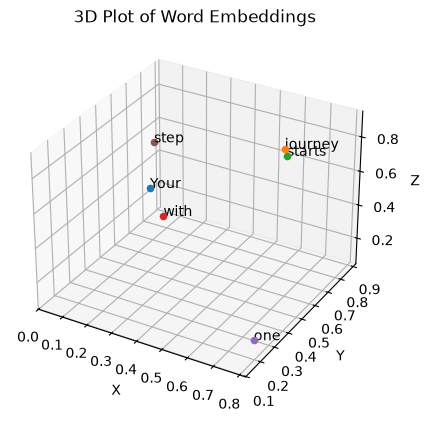

In [150]:
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D

# Corresponding words
words = ['Your', 'journey', 'starts', 'with', 'one', 'step']

# Extract x, y, z coordinates
x_coords = inputs[:, 0].numpy()
y_coords = inputs[:, 1].numpy()
z_coords = inputs[:, 2].numpy()

# Create 3D plot
fig = plt.figure()
ax = fig.add_subplot(111, projection='3d')

# Plot each point and annotate with corresponding word
for x, y, z, word in zip(x_coords, y_coords, z_coords, words):
    ax.scatter(x, y, z)
    ax.text(x, y, z, word, fontsize=10)

# Set labels for axes
ax.set_xlabel('X')
ax.set_ylabel('Y')
ax.set_zlabel('Z')

plt.title('3D Plot of Word Embeddings')
plt.show()

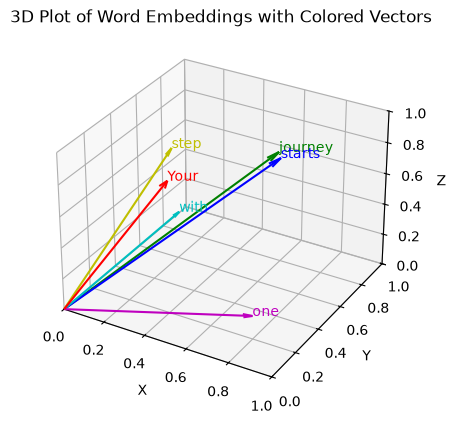

In [151]:
# Create 3D plot with vectors from origin to each point, using different colors
fig = plt.figure()
ax = fig.add_subplot(111, projection='3d')

# Define a list of colors for the vectors
colors = ['r', 'g', 'b', 'c', 'm', 'y']

# Plot each vector with a different color and annotate with the corresponding word
for (x, y, z, word, color) in zip(x_coords, y_coords, z_coords, words, colors):
    # Draw vector from origin to the point (x, y, z) with specified color and smaller arrow length ratio
    ax.quiver(0, 0, 0, x, y, z, color=color, arrow_length_ratio=0.05)
    ax.text(x, y, z, word, fontsize=10, color=color)

# Set labels for axes
ax.set_xlabel('X')
ax.set_ylabel('Y')
ax.set_zlabel('Z')

# Set plot limits to keep arrows within the plot boundaries
ax.set_xlim([0, 1])
ax.set_ylim([0, 1])
ax.set_zlim([0, 1])

plt.title('3D Plot of Word Embeddings with Colored Vectors')
plt.show()


### 1.2 Compute Attention Scores for One Query

Pick `"journey"` (index 1) as the query. The dot product of the query with each key measures similarity — how much the query should attend to that position.

In [152]:
query = inputs[1]  # "journey" is our query token

# dot product of query with every token (including itself)
attn_scores_2 = torch.empty(inputs.shape[0])
for idx, x_idx in enumerate(inputs):
    attn_scores_2[idx] = torch.dot(x_idx, query)

print(attn_scores_2)  # higher = more relevant to "journey"

tensor([0.9544, 1.4950, 1.4754, 0.8434, 0.7070, 1.0865])


### 1.3 Normalise Scores → Attention Weights

Three approaches — all convert raw scores to weights that sum to 1.

**Simple division** works only when all scores are positive. **Softmax** is the correct choice: `exp()` makes all values positive, then normalises.

In [153]:
# approach 1: simple division by sum (naive — breaks for negative scores)
attn_weights_2_tmp = attn_scores_2 / attn_scores_2.sum()
print(f"Simple norm:    {attn_weights_2_tmp}  sum={attn_weights_2_tmp.sum():.4f}")

# approach 2: L1 normalisation (same as above, different API)
import torch.nn.functional as F
print(f"F.normalize:    {F.normalize(attn_scores_2, p=1, dim=0)}")

Simple norm:    tensor([0.1455, 0.2278, 0.2249, 0.1285, 0.1077, 0.1656])  sum=1.0000
F.normalize:    tensor([0.1455, 0.2278, 0.2249, 0.1285, 0.1077, 0.1656])


In [154]:
# approach 3a: manual softmax — shows the formula explicitly
# exp() makes all values positive; dividing normalises to sum=1
def softmax_naive(x):
    return torch.exp(x) / torch.exp(x).sum(dim=0)

attn_weights_naive = softmax_naive(attn_scores_2)
print(f"Naive softmax:  {attn_weights_naive}  sum={attn_weights_naive.sum():.4f}")

Naive softmax:  tensor([0.1385, 0.2379, 0.2333, 0.1240, 0.1082, 0.1581])  sum=1.0000


In [155]:
# approach 3b: torch.softmax — numerically stable version (preferred)
attn_weights_2 = torch.softmax(attn_scores_2, dim=0)
print(f"torch.softmax:  {attn_weights_2}  sum={attn_weights_2.sum():.4f}")

torch.softmax:  tensor([0.1385, 0.2379, 0.2333, 0.1240, 0.1082, 0.1581])  sum=1.0000


### 1.4 Compute Context Vector

Weighted sum of all input vectors using the attention weights. The context vector for "journey" is a blend of all tokens, weighted by how relevant each is.

In [156]:
query = inputs[1]  # "journey"

context_vec_2 = torch.zeros(query.shape)
for idx, x_idx in enumerate(inputs):
    context_vec_2 += attn_weights_2[idx] * x_idx  # weighted sum

print(f"Context vector for 'journey': {context_vec_2}")
# This is a blend of all 6 token vectors — it now encodes what "journey" means in this sentence

Context vector for 'journey': tensor([0.4419, 0.6515, 0.5683])


### 1.5 All Tokens at Once — Full Attention Matrix

Compute context vectors for all 6 tokens simultaneously using matrix operations instead of Python loops.

In [157]:
# slow version: nested loops (shows the logic clearly)
attn_scores = torch.empty(6, 6)
for i, x_i in enumerate(inputs):
    for j, x_j in enumerate(inputs):
        attn_scores[i, j] = torch.dot(x_i, x_j)

attn_scores  # shape [6, 6]: row i = how much token i attends to every other token

tensor([[0.9995, 0.9544, 0.9422, 0.4753, 0.4576, 0.6310],
        [0.9544, 1.4950, 1.4754, 0.8434, 0.7070, 1.0865],
        [0.9422, 1.4754, 1.4570, 0.8296, 0.7154, 1.0605],
        [0.4753, 0.8434, 0.8296, 0.4937, 0.3474, 0.6565],
        [0.4576, 0.7070, 0.7154, 0.3474, 0.6654, 0.2935],
        [0.6310, 1.0865, 1.0605, 0.6565, 0.2935, 0.9450]])

In [158]:
# fast version: matrix multiplication (equivalent, vectorised)
# inputs @ inputs.T computes all dot products at once
attn_scores = inputs @ inputs.T
attn_scores

tensor([[0.9995, 0.9544, 0.9422, 0.4753, 0.4576, 0.6310],
        [0.9544, 1.4950, 1.4754, 0.8434, 0.7070, 1.0865],
        [0.9422, 1.4754, 1.4570, 0.8296, 0.7154, 1.0605],
        [0.4753, 0.8434, 0.8296, 0.4937, 0.3474, 0.6565],
        [0.4576, 0.7070, 0.7154, 0.3474, 0.6654, 0.2935],
        [0.6310, 1.0865, 1.0605, 0.6565, 0.2935, 0.9450]])

In [159]:
# softmax over each row (dim=-1) → each row sums to 1
attn_weights = torch.softmax(attn_scores, dim=-1)
attn_weights

tensor([[0.2098, 0.2006, 0.1981, 0.1242, 0.1220, 0.1452],
        [0.1385, 0.2379, 0.2333, 0.1240, 0.1082, 0.1581],
        [0.1390, 0.2369, 0.2326, 0.1242, 0.1108, 0.1565],
        [0.1435, 0.2074, 0.2046, 0.1462, 0.1263, 0.1720],
        [0.1526, 0.1958, 0.1975, 0.1367, 0.1879, 0.1295],
        [0.1385, 0.2184, 0.2128, 0.1420, 0.0988, 0.1896]])

In [160]:
# multiply attention weights by input values → all 6 context vectors at once
all_context_vecs = attn_weights @ inputs  # [6,6] @ [6,3] = [6,3]

print(f"inputs:\n{inputs}\n")
print(f"attn_weights:\n{attn_weights}\n")
print(f"all_context_vecs:\n{all_context_vecs}")
# row 1 (journey) matches context_vec_2 from the loop above

inputs:
tensor([[0.4300, 0.1500, 0.8900],
        [0.5500, 0.8700, 0.6600],
        [0.5700, 0.8500, 0.6400],
        [0.2200, 0.5800, 0.3300],
        [0.7700, 0.2500, 0.1000],
        [0.0500, 0.8000, 0.5500]])

attn_weights:
tensor([[0.2098, 0.2006, 0.1981, 0.1242, 0.1220, 0.1452],
        [0.1385, 0.2379, 0.2333, 0.1240, 0.1082, 0.1581],
        [0.1390, 0.2369, 0.2326, 0.1242, 0.1108, 0.1565],
        [0.1435, 0.2074, 0.2046, 0.1462, 0.1263, 0.1720],
        [0.1526, 0.1958, 0.1975, 0.1367, 0.1879, 0.1295],
        [0.1385, 0.2184, 0.2128, 0.1420, 0.0988, 0.1896]])

all_context_vecs:
tensor([[0.4421, 0.5931, 0.5790],
        [0.4419, 0.6515, 0.5683],
        [0.4431, 0.6496, 0.5671],
        [0.4304, 0.6298, 0.5510],
        [0.4671, 0.5910, 0.5266],
        [0.4177, 0.6503, 0.5645]])


## 2. Scaled Dot-Product Attention with Q, K, V Projections

Simple self-attention reuses the same vectors as query, key, and value. Real transformers project the input into **three separate learned spaces** using weight matrices `W_Q`, `W_K`, `W_V`.

This lets the model learn *what to look for* (query), *what to expose* (key), and *what to return* (value) independently.

```
Q = X @ W_Q    K = X @ W_K    V = X @ W_V
attn_scores  = Q @ K.T / sqrt(d_k)   # scaled dot product
attn_weights = softmax(attn_scores)
context_vecs = attn_weights @ V
```

In [161]:
import torch

inputs = torch.tensor(
    [[0.43, 0.15, 0.89],  # Your
     [0.55, 0.87, 0.66],  # journey
     [0.57, 0.85, 0.64],  # starts
     [0.22, 0.58, 0.33],  # with
     [0.77, 0.25, 0.10],  # one
     [0.05, 0.80, 0.55]]  # step
)

In [162]:
x_2  = inputs[1]        # "journey" — our single query token
d_in = inputs.shape[1]  # input dimension  = 3
d_out = 2               # output dimension = 2 (projected space)
d_in, d_out

(3, 2)

In [163]:
torch.manual_seed(123)

# W_Q, W_K, W_V are learned weight matrices (d_in → d_out)
# requires_grad=False here because we are just demonstrating forward pass
W_query = torch.nn.Parameter(torch.rand(d_in, d_out), requires_grad=False)
W_key   = torch.nn.Parameter(torch.rand(d_in, d_out), requires_grad=False)
W_value = torch.nn.Parameter(torch.rand(d_in, d_out), requires_grad=False)

In [164]:
print(f"W_query: \n{W_query}", end="\n\n")
print(f"W_key: \n{W_key}", end="\n\n")
print(f"W_value: \n{W_value}", end="\n\n")

W_query: 
Parameter containing:
tensor([[0.2961, 0.5166],
        [0.2517, 0.6886],
        [0.0740, 0.8665]])

W_key: 
Parameter containing:
tensor([[0.1366, 0.1025],
        [0.1841, 0.7264],
        [0.3153, 0.6871]])

W_value: 
Parameter containing:
tensor([[0.0756, 0.1966],
        [0.3164, 0.4017],
        [0.1186, 0.8274]])



In [165]:
# project a single token (x_2 = "journey") into Q, K, V spaces
queries_2 = x_2 @ W_query  # what "journey" is looking for
keys_2    = x_2 @ W_key    # what "journey" exposes to others
values_2  = x_2 @ W_value  # what "journey" returns if attended to

print(f"queries_2: {queries_2}")
print(f"keys_2:    {keys_2}")
print(f"values_2:  {values_2}")

queries_2: tensor([0.4306, 1.4551])
keys_2:    tensor([0.4433, 1.1419])
values_2:  tensor([0.3951, 1.0037])


In [166]:
# project all tokens at once (vectorised)
queries = inputs @ W_query  # [6, 2]
keys    = inputs @ W_key    # [6, 2]
values  = inputs @ W_value  # [6, 2]

print(f"queries shape: {queries.shape}")

queries shape: torch.Size([6, 2])


In [167]:
# dot product of query_2 with key_2 (single score, unscaled)
queries_2 @ keys_2

tensor(1.8524)

In [168]:
# attention scores for query_2 against ALL keys → shape [6]
attn_score_2 = queries_2 @ keys.T
attn_score_2

tensor([1.2705, 1.8524, 1.8111, 1.0795, 0.5577, 1.5440])

In [169]:
# attention scores for ALL queries against ALL keys → shape [6, 6]
attn_score = queries @ keys.T
attn_score

tensor([[0.9231, 1.3545, 1.3241, 0.7910, 0.4032, 1.1330],
        [1.2705, 1.8524, 1.8111, 1.0795, 0.5577, 1.5440],
        [1.2544, 1.8284, 1.7877, 1.0654, 0.5508, 1.5238],
        [0.6973, 1.0167, 0.9941, 0.5925, 0.3061, 0.8475],
        [0.6114, 0.8819, 0.8626, 0.5121, 0.2707, 0.7307],
        [0.8995, 1.3165, 1.2871, 0.7682, 0.3937, 1.0996]])

#### Why scale by √d_k?

With large `d_k`, dot products grow in magnitude, pushing softmax into saturation (one token gets ~all weight, gradients vanish). Dividing by `√d_k` keeps scores in a stable range.

In [170]:
import torch

# Define the tensor
tensor = torch.tensor([0.1, -0.2, 0.3, -0.2, 0.5])

# Apply softmax without scaling
softmax_result = torch.softmax(tensor, dim=-1)
print("Softmax without scaling:", softmax_result)

# Multiply the tensor by 8 and then apply softmax
scaled_tensor = tensor * 8
softmax_scaled_result = torch.softmax(scaled_tensor, dim=-1)
print("Softmax after scaling (tensor * 8):", softmax_scaled_result)

Softmax without scaling: tensor([0.1925, 0.1426, 0.2351, 0.1426, 0.2872])
Softmax after scaling (tensor * 8): tensor([0.0326, 0.0030, 0.1615, 0.0030, 0.8000])


In [171]:
d_k = keys.shape[-1]  # dimension of key vectors

# scaled softmax → stable attention weights for query_2
attn_weights_2 = torch.softmax(attn_score_2 / d_k**0.5, dim=-1)
attn_weights_2

tensor([0.1500, 0.2264, 0.2199, 0.1311, 0.0906, 0.1820])

In [172]:
# context vector for "journey": weighted sum of value vectors
attn_weights_2 @ values  # shape [2]

tensor([0.3061, 0.8210])

In [173]:
d_k = keys.shape[-1]

# scaled attention weights for all 6 tokens
attn_weights = torch.softmax(attn_score / d_k**0.5, dim=-1)
attn_weights  # shape [6, 6]

tensor([[0.1551, 0.2104, 0.2059, 0.1413, 0.1074, 0.1799],
        [0.1500, 0.2264, 0.2199, 0.1311, 0.0906, 0.1820],
        [0.1503, 0.2256, 0.2192, 0.1315, 0.0914, 0.1819],
        [0.1591, 0.1994, 0.1962, 0.1477, 0.1206, 0.1769],
        [0.1610, 0.1949, 0.1923, 0.1501, 0.1265, 0.1752],
        [0.1557, 0.2092, 0.2048, 0.1419, 0.1089, 0.1794]])

In [174]:
# context vectors for all tokens at once
attn_weights @ values  # shape [6, 2]

tensor([[0.2996, 0.8053],
        [0.3061, 0.8210],
        [0.3058, 0.8203],
        [0.2948, 0.7939],
        [0.2927, 0.7891],
        [0.2990, 0.8040]])

## 3. Self-Attention as an nn.Module

Package the scaled dot-product attention into a reusable PyTorch module.

### 3.1 SelfAttention_v1 — using nn.Parameter

Weight matrices stored as raw `nn.Parameter` tensors. Simple but uses `@` for projection.

In [175]:
import torch.nn as nn

class SelfAttention_v1(nn.Module):
    def __init__(self, d_in, d_out):
        super().__init__()
        # learnable weight matrices for query, key, value projections
        self.W_query = nn.Parameter(torch.rand(d_in, d_out))
        self.W_key   = nn.Parameter(torch.rand(d_in, d_out))
        self.W_value = nn.Parameter(torch.rand(d_in, d_out))

    def forward(self, x):
        keys    = x @ self.W_key
        values  = x @ self.W_value
        queries = x @ self.W_query

        attn_score  = queries @ keys.T
        attn_weight = torch.softmax(attn_score / keys.shape[-1]**0.5, dim=-1)
        return attn_weight @ values

In [176]:
torch.manual_seed(123)
sa_v1 = SelfAttention_v1(d_in, d_out)
sa_v1(inputs)

tensor([[0.2996, 0.8053],
        [0.3061, 0.8210],
        [0.3058, 0.8203],
        [0.2948, 0.7939],
        [0.2927, 0.7891],
        [0.2990, 0.8040]], grad_fn=<MmBackward0>)

### 3.2 SelfAttention_v2 — using nn.Linear

`nn.Linear` is preferred over raw `nn.Parameter` — it handles weight initialisation correctly and optionally adds bias. Internally it does the same `x @ W.T` projection.

In [177]:
class SelfAttention_v2(nn.Module):
    def __init__(self, d_in, d_out, qkv_bias=False):
        super().__init__()
        # nn.Linear is cleaner than nn.Parameter: proper init + optional bias
        self.W_query = nn.Linear(d_in, d_out, bias=qkv_bias)
        self.W_key   = nn.Linear(d_in, d_out, bias=qkv_bias)
        self.W_value = nn.Linear(d_in, d_out, bias=qkv_bias)

    def forward(self, x):
        keys    = self.W_key(x)
        values  = self.W_value(x)
        queries = self.W_query(x)

        attn_score  = queries @ keys.T
        attn_weight = torch.softmax(attn_score / keys.shape[-1]**0.5, dim=-1)
        return attn_weight @ values

In [178]:
torch.manual_seed(123)
sa_v1 = SelfAttention_v2(d_in, d_out)
sa_v1(inputs)

tensor([[-0.5337, -0.1051],
        [-0.5323, -0.1080],
        [-0.5323, -0.1079],
        [-0.5297, -0.1076],
        [-0.5311, -0.1066],
        [-0.5299, -0.1081]], grad_fn=<MmBackward0>)